### Task 1
For the statement 1 of task 1, we are going to implement the gradient descent method with backtracking from the Practical 2, where we defined it previously. Observe that we modify the parameters of the functions $f$ and $df$, so they have into account the set of sample points. Also, we added the condition of alpha>1e-12 because elsewise the alpha approximates to practically 0, and the inner loop never stops, because there is very little variation in the actual point and the next point (numerically). Also, we add that if alpha is less or equal than 1e-12, then the algorithm stops. 


In [119]:

def gradient_descent_backtrack(f, df, starting_point, points):
    
    (x_1, x_2) = starting_point
    traj_points = [(x_1, x_2)]
    while True:
        gradient = df(points, x_1, x_2)
        if np.linalg.norm(gradient) < 1e-5: # we arbitrarily choose this as tolerance.
            break

        alpha=1
        while alpha>1e-12 and f(points, x_1, x_2) <= f(points, x_1 - alpha*gradient[0], x_2 - alpha*gradient[1]):
            alpha = alpha/2
        if alpha <= 1e-12:
            break
        x_1 -= alpha*gradient[0]
        x_2 -= alpha*gradient[1]
        traj_points.append((x_1, x_2))

    return traj_points

        

In [120]:
import math
import numpy as np

m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle),-math.sin(angle)], [math.sin(angle),
math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
points = np.random.multivariate_normal(m,s,100)


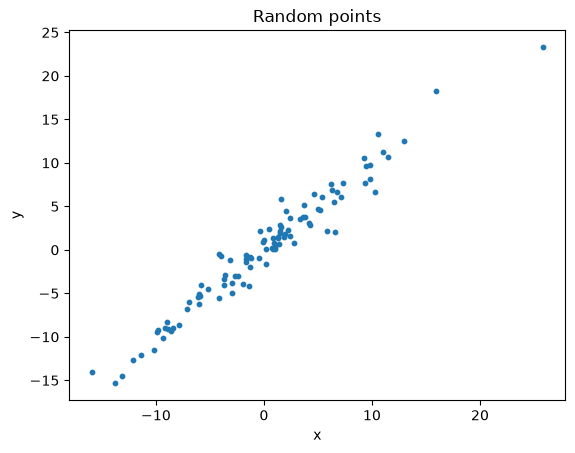

In [121]:
import matplotlib.pyplot as plt

plt.scatter(points[:, 0], points[:, 1], s=10)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Random points")
#plt.axis("equal") #Hace falta o lo quitamos? Solamente hace que el plot sea cuadrado. 
plt.show()

To approach the problem, we first define the function and it's derivative. 

In [122]:
def Q(points, w_0, w_1):
    w=0
    for i in range(len(points)):
        w += (1/2)*(w_0*points[i][0] + w_1 - points[i][1])**2
    return w

def dQ(points, w_0, w_1):
    dw0=0
    dw1=0
    for i in range(len(points)):
        comsum = (w_0*points[i][0] + w_1 - points[i][1])
        dw0 += comsum*points[i][0]
        dw1 += comsum
    return np.array([dw0, dw1])



Now, having defined the definition of functions, we intend to find the minimum values of $(w_0, w_1)$ using `gradient_descent_backtrack`:

In [123]:
path = gradient_descent_backtrack(Q, dQ, (1,2), points)


Now, having found the values of $(w_0, w_1)$ that minimise the least squares error function, we can draw a plot of how "good" does the line with these values fit the points:

Text(0.5, 1.0, 'Random points')

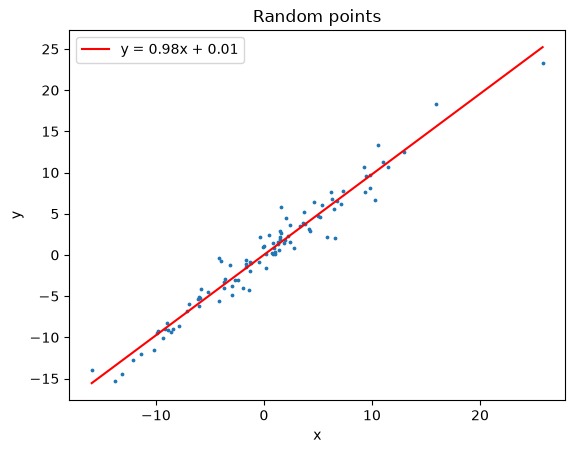

In [124]:
plt.scatter(points[:, 0], points[:, 1], s=3)
x_line = np.array([points[:, 0].min(), points[:, 0].max()])
plt.plot(x_line, path[-1][0]*x_line + path[-1][1], color="red", label=f"y = {path[-1][0]:.2f}x + {path[-1][1]:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Random points")

So we observe that with the parameters extracted using gradient descent, the line fits very well to the sample points. In reality, what it does is minimises the average distance from the real sample point $y$, to what we reach with the linear regression, say $\hat{y}$. 

For statement 2, let's edit the code of sample points so there is an outlier, and see how the line with new parameters $(\tilde{w_0}, \tilde{w_1})$ behave. 

In [125]:
m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle),-math.sin(angle)], [math.sin(angle),
math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
points_outl1 = np.random.multivariate_normal(m,s,100)
points_outl1[1] = [-40, 20]

In [126]:
path_ = gradient_descent_backtrack(Q, dQ, (1,2), points_outl1)


Text(0.5, 1.0, 'Random points w/ outlier')

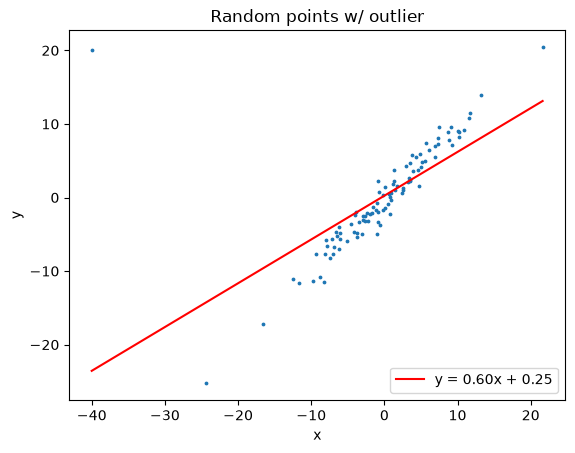

In [127]:
plt.scatter(points_outl1[:, 0], points_outl1[:, 1], s=3)
x_line_ = np.array([points_outl1[:, 0].min(), points_outl1[:, 0].max()])
plt.plot(x_line_, path_[-1][0]*x_line_ + path_[-1][1], color="red", label=f"y = {path_[-1][0]:.2f}x + {path_[-1][1]:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Random points w/ outlier")


We can observe that due to the outlier points $X = [-40, 20]$, values of parameters $(w_0, w_1)$ are changed because the function also had to minimize the value of $(\hat{x}, \hat{y})$ relative to $X$. 